In [45]:
!pip install pandas



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: C:\Users\simon\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [46]:
!pip install scikit-learn


[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: C:\Users\simon\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [47]:
import sys
!{sys.executable} -m pip install matplotlib



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: C:\Users\simon\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [48]:
import sys
!{sys.executable} -m pip install seaborn



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: C:\Users\simon\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [49]:
import pandas as pd 
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
df = pd.read_csv('EV_Battery_Fault_Diagnosis.csv')

df.head()

,Time (ms),Voltage (V),Current (A),Temperature (°C),Motor Speed (RPM),Hall Code,Estimated SOC (%),Ground Truth SOC (%),Residual (%),Fault Label
0,0,3.65,3.74,21.5,1350,111,88.7,87.7,1.0,Normal
1,100,3.59,2.33,35.3,1263,10,90.0,90.4,0.4,Normal
2,200,3.66,1.23,31.0,1267,10,97.9,98.6,0.7,Normal
3,300,3.75,2.50,38.2,1320,0,92.9,90.6,2.3,Warning
4,400,3.58,4.78,33.1,1290,1,92.9,92.2,0.7,Normal


In [51]:
df.isnull().sum()

Time (ms)               0
Voltage (V)             0
Current (A)             0
Temperature (°C)        0
Motor Speed (RPM)       0
Hall Code               0
Estimated SOC (%)       0
Ground Truth SOC (%)    0
Residual (%)            0
Fault Label             0
dtype: int64

NameError: name 'y' is not defined

In [58]:
X = df.drop('Fault Label', axis=1)
y = df["Fault Label"]

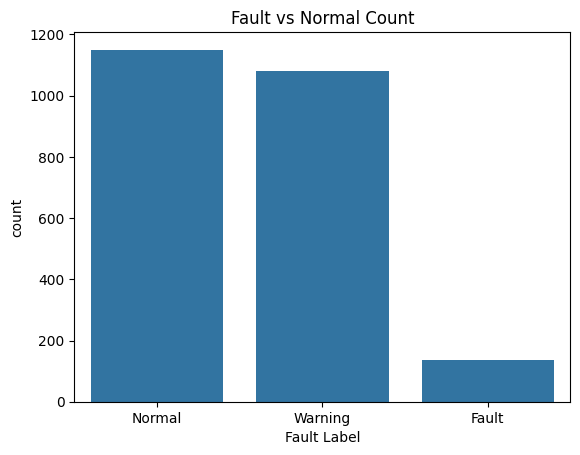

In [59]:
# exploratory data visualization
sns.countplot(x=y)
plt.title("Fault vs Normal Count")
plt.show()



In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [61]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [62]:
y_pred = model.predict(X_test)
y_pred



array(['Normal', 'Warning', 'Warning', 'Normal', 'Normal', 'Normal',
       'Normal', 'Warning', 'Warning', 'Warning', 'Warning', 'Normal',
       'Normal', 'Normal', 'Warning', 'Normal', 'Warning', 'Fault',
       'Warning', 'Warning', 'Normal', 'Warning', 'Warning', 'Warning',
       'Warning', 'Warning', 'Normal', 'Normal', 'Normal', 'Normal',
       'Normal', 'Normal', 'Normal', 'Normal', 'Warning', 'Normal',
       'Warning', 'Warning', 'Normal', 'Warning', 'Warning', 'Warning',
       'Warning', 'Normal', 'Normal', 'Normal', 'Warning', 'Warning',
       'Warning', 'Normal', 'Normal', 'Warning', 'Warning', 'Warning',
       'Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Fault',
       'Warning', 'Normal', 'Normal', 'Warning', 'Warning', 'Normal',
       'Warning', 'Warning', 'Normal', 'Warning', 'Warning', 'Warning',
       'Warning', 'Normal', 'Normal', 'Normal', 'Warning', 'Normal',
       'Normal', 'Warning', 'Normal', 'Fault', 'Normal', 'Warning',
       'Warning', 'Warnin

In [63]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)




Accuracy: 1.0


In [64]:
#evaluate the model

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

       Fault       1.00      1.00      1.00        34
      Normal       1.00      1.00      1.00       226
     Warning       1.00      1.00      1.00       214

    accuracy                           1.00       474
   macro avg       1.00      1.00      1.00       474
weighted avg       1.00      1.00      1.00       474



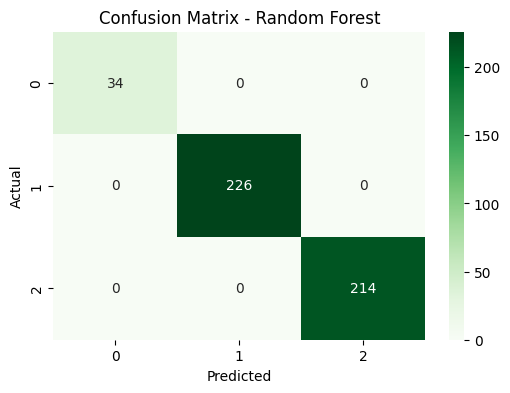

In [65]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()


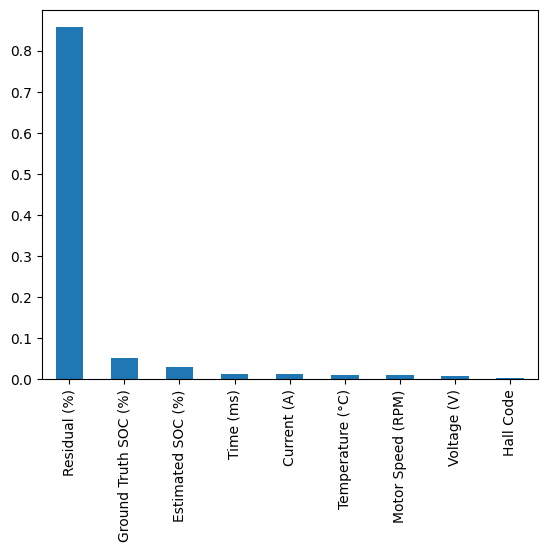

In [66]:
importances = model.feature_importances_

pd.Series(importances, index=X.columns)\
  .sort_values(ascending=False)\
  .plot(kind="bar")
plt.show()


In [67]:
#model comparison...

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)



C:\Users\simon\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [68]:
from sklearn.svm import SVC

svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True
)
svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)


In [69]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)


In [71]:
from sklearn.metrics import accuracy_score, recall_score, f1_score


results = []

models_preds = {
    "Logistic Regression": lr_pred,
    "SVM": svm_pred,
    "Random Forest": rf_pred
}


for name, pred in models_preds.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Recall (weighted)": recall_score(y_test, pred, average="weighted"),
        "F1-score (weighted)": f1_score(y_test, pred, average="weighted")
    })

comparison_df = pd.DataFrame(results)
comparison_df


,Model,Accuracy,Recall (weighted),F1-score (weighted)
0,Logistic Regression,0.751055,0.751055,0.752373
1,SVM,0.286920,0.286920,0.242974
2,Random Forest,1.000000,1.000000,1.000000


In [72]:
!pip install joblib



[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: C:\Users\simon\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [73]:
import joblib
joblib.dump(model, "battery_fault_model.pkl")
loaded_model = joblib.load("battery_fault_model.pkl")
